In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('Predict.students.csv')

In [3]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
df.shape

(4424, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [6]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,18.000000,9.000000,17.000000,1.000000,17.000000,21.000000,29.000000,34.000000,32.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [7]:
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrollment                                 0
International                                     0
Curricular u

In [8]:
df.duplicated().sum()

0

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


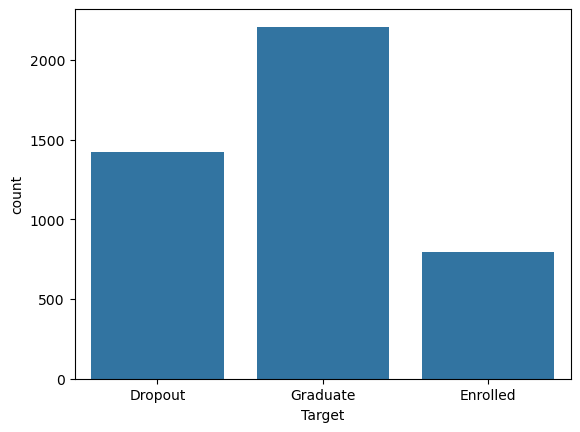

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
print(df['Target'].value_counts())
sns.countplot(x='Target', data=df)
plt.show()

In [10]:
df = df[df['Target'] != 'Enrolled'].reset_index(drop=True)
print(df.shape)
print(df['Target'].value_counts())

(3630, 35)
Target
Graduate    2209
Dropout     1421
Name: count, dtype: int64


In [11]:
# Separate features and target
X = df.drop(columns='Target')   # all columns except Target
y = df['Target']                # what we predict: Dropout / Graduate

print(X.shape)
print(y.shape)

(3630, 34)
(3630,)


In [12]:
## Encoding Categorical Variables

# Nominal columns stored as number codes
nominal_cols = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
                'Nacionality', "Mother's qualification", "Father's qualification",
                "Mother's occupation", "Father's occupation"]

# Convert categorical variables into dummy (0/1) columns
X = pd.get_dummies(X, columns=nominal_cols, drop_first=True, dtype=int)

print(X.shape)

(3630, 227)


In [13]:
# Check the new shape
X.shape
X.head(10)

,Application order,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,...,Father's occupation_37,Father's occupation_38,Father's occupation_39,Father's occupation_40,Father's occupation_41,Father's occupation_42,Father's occupation_43,Father's occupation_44,Father's occupation_45,Father's occupation_46
0,5,1,1,0,0,1,1,0,20,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,1,0,19,0,...,0,0,0,0,0,0,0,0,0,0
2,5,1,1,0,0,0,1,0,19,0,...,0,0,0,0,0,0,0,0,0,0
3,2,1,1,0,0,1,0,0,20,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,1,0,0,45,0,...,0,0,0,0,0,0,0,0,0,0
5,1,0,0,0,1,1,1,0,50,0,...,0,0,0,0,0,0,0,0,0,0
6,1,1,1,0,0,1,0,1,18,0,...,0,0,0,0,0,0,0,0,0,0
7,4,1,1,0,0,0,1,0,22,0,...,0,0,0,0,0,0,0,0,0,0
8,3,1,0,0,0,1,0,1,21,1,...,0,0,0,0,0,0,0,0,0,0
9,1,1,1,0,1,0,0,0,18,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
## Data Splitting (5% test)
from sklearn.model_selection import train_test_split

# Split the data into training (95%) and testing (5%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05,
                                                    stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(3448, 227) (182, 227)


In [15]:
# Create the model
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

lr_model = Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [16]:
# Train the model
lr_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [17]:
# Make predictions on test data
y_pred_lr = lr_model.predict(X_test)

In [18]:
# Evaluate the model
from sklearn.metrics import accuracy_score, f1_score

# Accuracy closer to 1 is better (% of students predicted correctly)
# F1 closer to 1 is better (balance between precision and recall)
print("Logistic Regression test size is 5%")
print("Train Accuracy:", accuracy_score(y_train, lr_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr, average='weighted'))

Logistic Regression test size is 5%
Train Accuracy: 0.9254640371229699
Test Accuracy: 0.9010989010989011
F1 Score: 0.9008339874411303


In [19]:
# Cross-validation (more reliable evaluation)
from sklearn.model_selection import cross_val_score

lr_cv = cross_val_score(lr_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV Accuracy for each fold:", lr_cv)
print("CV mean Accuracy:", lr_cv.mean())

CV Accuracy for each fold: [0.89710145 0.8826087  0.91884058 0.91001451 0.91001451]
CV mean Accuracy: 0.9037159504427758


In [20]:
# Create the model - Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([('scaler', StandardScaler()),
                     ('clf', RandomForestClassifier(n_estimators=100, random_state=42))])

In [21]:
# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on test data
y_pred_rf = rf_model.predict(X_test)

In [22]:
# Evaluate the model
print("Random Forest test size is 5%")
print("Train Accuracy:", accuracy_score(y_train, rf_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf, average='weighted'))

# Cross-validation (more reliable evaluation)
rf_cv = cross_val_score(rf_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV Accuracy for each fold:", rf_cv)
print("CV mean Accuracy:", rf_cv.mean())

Random Forest test size is 5%
Train Accuracy: 1.0
Test Accuracy: 0.945054945054945
F1 Score: 0.9445658830333753
CV Accuracy for each fold: [0.89275362 0.89565217 0.9115942  0.90566038 0.92162554]
CV mean Accuracy: 0.9054571843251088


In [25]:
# Create the model - Support Vector Machine
from sklearn.svm import SVC

svm_model = Pipeline([('scaler', StandardScaler()),
                      ('clf', SVC(kernel='rbf', random_state=42))])

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions on test data
y_pred_svm = svm_model.predict(X_test)

In [26]:
# Evaluate the model
print("SVM test size is 5%")
print("Train Accuracy:", accuracy_score(y_train, svm_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm, average='weighted'))

# Cross-validation (more reliable evaluation)
svm_cv = cross_val_score(svm_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV Accuracy for each fold:", svm_cv)
print("CV mean Accuracy:", svm_cv.mean())

SVM test size is 5%
Train Accuracy: 0.9379350348027842
Test Accuracy: 0.8736263736263736
F1 Score: 0.8718123981281877
CV Accuracy for each fold: [0.86666667 0.86956522 0.88550725 0.85921626 0.88679245]
CV mean Accuracy: 0.8735495677415284


In [27]:
# Data Splitting (15% test)
# Split the data into training (85%) and testing (15%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15,
                                                    stratify=y, random_state=42)
print(X_train.shape, X_test.shape)


(3085, 227) (545, 227)


In [28]:
# Logistic Regression - test size 15%
lr_model = Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000, random_state=42))])
lr_model.fit(X_train, y_train)            # Train the model
y_pred_lr = lr_model.predict(X_test)      # Make predictions on test data

# Evaluate the model
print("Logistic Regression test size is 15%")
print("Train Accuracy:", accuracy_score(y_train, lr_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr, average='weighted'))

Logistic Regression test size is 15%
Train Accuracy: 0.9280388978930308
Test Accuracy: 0.8990825688073395
F1 Score: 0.8982448782942604


In [29]:
lr_cv = cross_val_score(lr_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean Accuracy:", lr_cv.mean())

CV mean Accuracy: 0.9053484602917342


In [30]:
# Random Forest - test size 15%
rf_model = Pipeline([('scaler', StandardScaler()),
                     ('clf', RandomForestClassifier(n_estimators=100, random_state=42))])
rf_model.fit(X_train, y_train)            # Train the model
y_pred_rf = rf_model.predict(X_test)      # Make predictions on test data

# Evaluate the model
print("Random Forest test size is 15%")
print("Train Accuracy:", accuracy_score(y_train, rf_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf, average='weighted'))

# Cross-validation
rf_cv = cross_val_score(rf_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean Accuracy:", rf_cv.mean())

Random Forest test size is 15%
Train Accuracy: 1.0
Test Accuracy: 0.9211009174311927
F1 Score: 0.9199728433259358
CV mean Accuracy: 0.905996758508914


In [31]:
# SVM - test size 15%
svm_model = Pipeline([('scaler', StandardScaler()),
                      ('clf', SVC(kernel='rbf', random_state=42))])
svm_model.fit(X_train, y_train)           # Train the model
y_pred_svm = svm_model.predict(X_test)    # Make predictions on test data

# Evaluate the model
print("SVM test size is 15%")
print("Train Accuracy:", accuracy_score(y_train, svm_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm, average='weighted'))

# Cross-validation
svm_cv = cross_val_score(svm_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean Accuracy:", svm_cv.mean())

SVM test size is 15%
Train Accuracy: 0.9377633711507294
Test Accuracy: 0.8844036697247707
F1 Score: 0.881956845619843
CV mean Accuracy: 0.8764991896272285


In [32]:
# Data Splitting (25% test)
# Split the data into training (75%) and testing (25%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                    stratify=y, random_state=42)

In [33]:
# Logistic Regression - test size 25%
lr_model = Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000, random_state=42))])
lr_model.fit(X_train, y_train)            # Train the model
y_pred_lr = lr_model.predict(X_test)      # Make predictions on test data

# Evaluate the model
print("Logistic Regression test size is 25%")
print("Train Accuracy:", accuracy_score(y_train, lr_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr, average='weighted'))

# Cross-validation
lr_cv = cross_val_score(lr_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean Accuracy:", lr_cv.mean())

Logistic Regression test size is 25%
Train Accuracy: 0.9342395297575312
Test Accuracy: 0.8920704845814978
F1 Score: 0.8911148120909964
CV mean Accuracy: 0.905584862385321


In [34]:
# Random Forest - test size 25%
rf_model = Pipeline([('scaler', StandardScaler()),
                     ('clf', RandomForestClassifier(n_estimators=100, random_state=42))])
rf_model.fit(X_train, y_train)            # Train the model
y_pred_rf = rf_model.predict(X_test)      # Make predictions on test data

# Evaluate the model
print("Random Forest test size is 25%")
print("Train Accuracy:", accuracy_score(y_train, rf_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf, average='weighted'))

# Cross-validation
rf_cv = cross_val_score(rf_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean Accuracy:", rf_cv.mean())

Random Forest test size is 25%
Train Accuracy: 1.0
Test Accuracy: 0.9074889867841409
F1 Score: 0.9057574516633402
CV mean Accuracy: 0.9081651376146789


In [35]:
# SVM - test size 25%
svm_model = Pipeline([('scaler', StandardScaler()),
                      ('clf', SVC(kernel='rbf', random_state=42))])
svm_model.fit(X_train, y_train)           # Train the model
y_pred_svm = svm_model.predict(X_test)    # Make predictions on test data

# Evaluate the model
print("SVM test size is 25%")
print("Train Accuracy:", accuracy_score(y_train, svm_model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm, average='weighted'))

# Cross-validation
svm_cv = cross_val_score(svm_model, X_train, y_train, cv=5, scoring="accuracy")
print("CV mean Accuracy:", svm_cv.mean())

SVM test size is 25%
Train Accuracy: 0.9426891991182954
Test Accuracy: 0.8722466960352423
F1 Score: 0.8691807848838222
CV mean Accuracy: 0.8798725040474906


                 Model Split  Train Accuracy  Test Accuracy  F1 Score  \
0  Logistic Regression    5%          0.9255         0.9011    0.9008   
1        Random Forest    5%          1.0000         0.9451    0.9446   
2                  SVM    5%          0.9379         0.8736    0.8718   
3  Logistic Regression   15%          0.9280         0.8991    0.8982   
4        Random Forest   15%          1.0000         0.9211    0.9200   
5                  SVM   15%          0.9378         0.8844    0.8820   
6  Logistic Regression   25%          0.9342         0.8921    0.8911   
7        Random Forest   25%          1.0000         0.9075    0.9058   
8                  SVM   25%          0.9427         0.8722    0.8692   

   CV Accuracy  
0       0.9037  
1       0.9055  
2       0.8735  
3       0.9053  
4       0.9060  
5       0.8765  
6       0.9056  
7       0.9082  
8       0.8799  


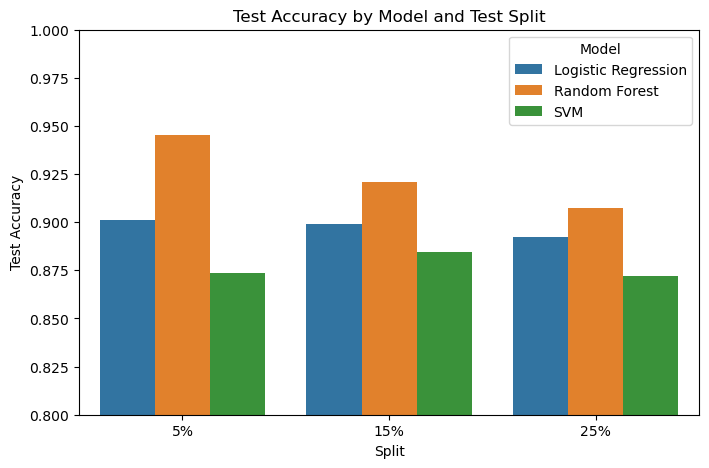

In [37]:
# Summary of results across the three splits
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "SVM"] * 3,
    "Split": ["5%"]*3 + ["15%"]*3 + ["25%"]*3,
    "Train Accuracy": [0.9255, 1.0000, 0.9379,  0.9280, 1.0000, 0.9378,  0.9342, 1.0000, 0.9427],
    "Test Accuracy":  [0.9011, 0.9451, 0.8736,  0.8991, 0.9211, 0.8844,  0.8921, 0.9075, 0.8722],
    "F1 Score":       [0.9008, 0.9446, 0.8718,  0.8982, 0.9200, 0.8820,  0.8911, 0.9058, 0.8692],
    "CV Accuracy":    [0.9037, 0.9055, 0.8735,  0.9053, 0.9060, 0.8765,  0.9056, 0.9082, 0.8799]
})
print(results_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Split", y="Test Accuracy", hue="Model")
plt.ylim(0.8, 1.0)
plt.title("Test Accuracy by Model and Test Split")
plt.show()

In [38]:
# Hyperparameter tuning using GridSearchCV (25% split)
from sklearn.model_selection import GridSearchCV

# Models
classifiers = {
    "Logistic Regression": Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    "Random Forest": Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]),
    "SVM": Pipeline([('scaler', StandardScaler()), ('clf', SVC(random_state=42))])
}

# Hyperparameter grids for each classifier ('clf__' = the classifier inside the Pipeline)
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10], "clf__solver": ['lbfgs', 'liblinear']},
    "Random Forest": {"clf__n_estimators": [100, 200], "clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 2, 4]},
    "SVM": {"clf__C": [0.1, 1, 10], "clf__kernel": ['linear', 'rbf'], "clf__gamma": ['scale', 'auto']}
}

# Apply GridSearchCV for each classifier and evaluate on the test set
results = []
best_models = {}
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(classifier, param_grids[name], cv=5, scoring='accuracy', n_jobs=-1)
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    best_models[name] = best_model
    y_pred = best_model.predict(X_test)

    results.append([name, grid_search.best_params_, grid_search.best_score_,
                    accuracy_score(y_train, best_model.predict(X_train)),
                    accuracy_score(y_test, y_pred)])

tuned_df = pd.DataFrame(results, columns=["Model", "Best Parameters", "Best CV Accuracy", "Train Accuracy", "Test Accuracy"])
pd.set_option('display.max_colwidth', None)
print(tuned_df)

Running GridSearchCV for Logistic Regression...
Running GridSearchCV for Random Forest...
Running GridSearchCV for SVM...
                 Model  \
0  Logistic Regression   
1        Random Forest   
2                  SVM   

                                                                  Best Parameters  \
0                                     {'clf__C': 0.1, 'clf__solver': 'liblinear'}   
1  {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}   
2                 {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}   

   Best CV Accuracy  Train Accuracy  Test Accuracy  
0          0.905953        0.932403       0.904185  
1          0.908165        1.000000       0.907489  
2          0.912572        0.933137       0.906388  


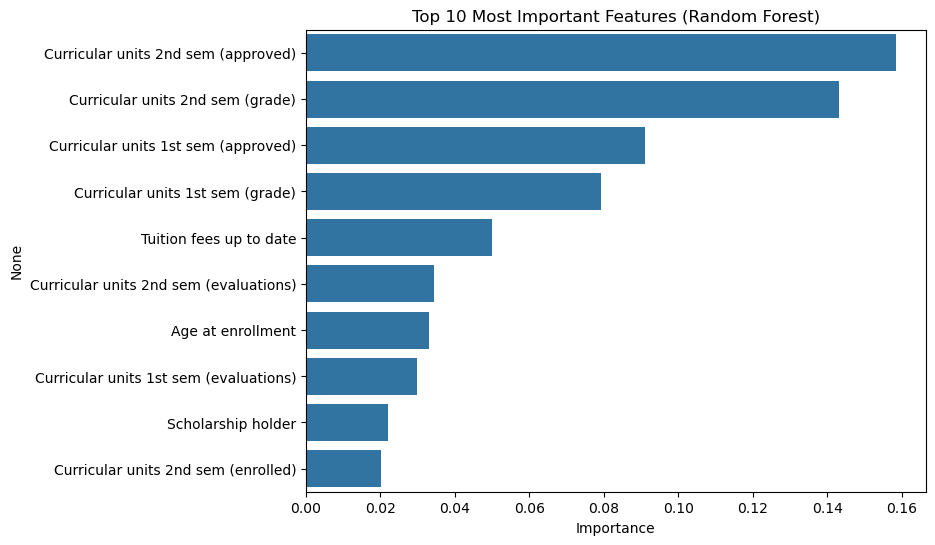

                                  Feature  F-statistic  p-value
0     Curricular units 2nd sem (approved)    2711.4409   0.0000
1        Curricular units 2nd sem (grade)    2098.4509   0.0000
2     Curricular units 1st sem (approved)    1613.9623   0.0000
3        Curricular units 1st sem (grade)    1344.0710   0.0000
4                 Tuition fees up to date     881.5528   0.0000
5  Curricular units 2nd sem (evaluations)      52.3265   0.0000
6                       Age at enrollment     279.0053   0.0000
7  Curricular units 1st sem (evaluations)      13.0144   0.0003
8                      Scholarship holder     394.0840   0.0000
9     Curricular units 2nd sem (enrolled)     125.5609   0.0000


In [39]:
# Feature importance from the tuned Random Forest
rf = best_models["Random Forest"].named_steps['clf']
feature_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=feature_imp.head(10).values, y=feature_imp.head(10).index)
plt.title("Top 10 Most Important Features (Random Forest)")
plt.xlabel("Importance")
plt.show()

# Statistical significance: ANOVA F-test (p-value < 0.05 = significant difference between Dropout and Graduate)
from sklearn.feature_selection import f_classif
F, p = f_classif(X[feature_imp.head(10).index], y)
stats_df = pd.DataFrame({"Feature": feature_imp.head(10).index, "F-statistic": F, "p-value": p})
print(stats_df.round(4))